**Reproducibility note:** The following analyses were executed against `data/processed/master.csv`. Numeric statements refer to observed data; the EDA examines the corpus, not independently verified chatbot performance.

# **Project Name — RAAI-SGC 2.0: IT Knowledge Assistant Dataset EDA**


##### **Project Type** — NLP / Knowledge Graph / EDA (not ordinary tabular regression)
##### **Contribution** — Enter your actual individual/team details
##### **Team Member(s)** — *Fill in personally*


# **Project Summary -**

This exploratory data analysis (EDA) examines the candidate knowledge corpus supporting RAAI-SGC 2.0, an industry-focused question-answering assistant for artificial intelligence and machine learning, cloud and DevOps, cybersecurity, and software engineering. The business objective is not to forecast sales or diagnose users. It is to assess whether the collected Wikipedia-derived evidence is sufficiently traceable and structurally consistent for subsequent retrieval, human review, and controlled experimentation with Markov–TF-IDF weighted graph augmentation. The study uses the unchanged `data/master.csv` file provided with the Colab-only project folder.

The dataset contains **5,206 rows and 32 columns**, but these are three different record populations: **145 SOURCE passages**, **4,771 EDGE associations**, and **290 QA_DRAFT records**. Each source contributes two draft questions. Graph edges and draft questions inherit their source identifiers, so they are not treated as additional independent article examples. To avoid misleading sample counts and train/test leakage, descriptive passage-level statistics use SOURCE records, graph statistics use EDGE records, and draft-question analyses use QA_DRAFT records. Raw source text is retained, and record IDs, source references, existing splits, and the prescribed edge-weight arithmetic are checked.

The 145 sources cover **40 AI/ML**, **32 Cloud & DevOps**, **36 Cybersecurity**, and **37 Software Engineering** articles. The existing split contains **116 training**, **14 validation**, and **15 test** sources. Article passages have a median length of **156 words**, a mean of **178.04 words**, and a range of **26 to 583 words**. Cloud & DevOps has a median of **101 words**, compared with **188.5** in AI/ML and **189.5** in Cybersecurity. This variation can matter when retrieval systems rank passages of different lengths. It does not establish that any one domain has better source quality.

Graph extraction produces a median of **30 edges per source** and a mean of **32.90**, with a range of **7 to 87**. Passage word count and edge count are highly associated (**Pearson r = 0.937**), plausibly because longer articles expose more extractable phrases. The most frequent graph targets include **“service” (17)** and **“machine learning” (16)**. These patterns suggest that generic targets and graph density should be audited before relying on graph expansion. Mean observed edge weight is **0.0293** in AI/ML and **0.0478** in Cloud & DevOps; those numbers are features of the scoring procedure, not measurements of factual correctness.

The dataset passes the notebook’s structural assertions, including uniqueness and the weight formula. However, **all 145 sources remain UNREVIEWED**, and their licensing state is **REVIEW_CC_BY_SA**. The **290 Q&A entries are drafts**, not verified reference answers. Consequently, the corpus is an engineering candidate rather than a licensed, human-approved benchmark or supervised fine-tuning dataset.

The practical outcome is a prioritized quality plan: review source facts and attributions, examine short passages and generic graph targets, retain source-grouped splits, and collect independently approved evaluation questions. Later GraphRAG experiments must compare vector-only, unweighted graph, and Markov–TF-IDF weighted retrieval under matched budgets. This EDA describes dataset readiness and limitations only; it cannot demonstrate chatbot accuracy or superiority of graph-augmented retrieval.

# **GitHub Link -**

**Repository:** Add your actual GitHub URL after publishing; do not invent one.


# **Problem Statement**


Develop a reproducible descriptive audit of IT knowledge sources and weighted graph records. The primary challenge is distinguishing three record types and identifying coverage, provenance, class imbalance, incomplete reviews, graph artifacts and evidence-integrity problems without treating edges as independent observations.


#### **Define Your Business Objective?**

Provide engineering evidence for the industry-specific chatbot: domain coverage, source traceability, graph-weight distributions, review readiness, and data-quality limitations. These are dataset-quality indicators, **not** chatbot performance metrics.


# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Colab / local notebook bootstrap. Upload only the RAAI_SGC_EDA_ML_COLAB_ONLY folder to Google Drive.
from pathlib import Path
import os, sys, json, re, csv, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
try:
    import google.colab
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    pass
PROJECT_NAME = 'RAAI_SGC_EDA_ML_COLAB_COMPLETED'
CANDIDATES = [Path('/content/drive/MyDrive')/PROJECT_NAME,
              Path('/content')/PROJECT_NAME, Path.cwd(), Path.cwd().parent,
              Path('/mnt/data')/PROJECT_NAME]
PROJECT_ROOT = next((p.resolve() for p in CANDIDATES if (p/'data/master.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Upload/extract RAAI_SGC_2_COMPLETE_PROJECT to MyDrive, then rerun this cell; required data/master.csv not found.')
MASTER_CSV = PROJECT_ROOT/'data/master.csv'
REPORT_DIR = PROJECT_ROOT/'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print('Project:',PROJECT_ROOT, '\nData:',MASTER_CSV)

Project: /mnt/data/RAAI_SGC_EDA_ML_COLAB_COMPLETED 
Data: /mnt/data/RAAI_SGC_EDA_ML_COLAB_COMPLETED/data/master.csv


### Dataset Loading

In [2]:
df = pd.read_csv(MASTER_CSV, dtype=str, keep_default_na=False, encoding='utf-8-sig')
required={'record_id','record_type','source_id','domain','split','source_title','source_text','source_url','edge_weight','markov_probability','tfidf_score'}
assert required.issubset(df.columns), f'Missing columns: {required-set(df.columns)}'
sources=df.loc[df.record_type.eq('SOURCE')].copy().drop_duplicates('source_id')
edges=df.loc[df.record_type.eq('EDGE')].copy()
qa=df.loc[df.record_type.eq('QA_DRAFT')].copy()
for name in ('edge_weight','markov_probability','tfidf_score'):
    edges[name]=pd.to_numeric(edges[name],errors='coerce')
sources['text_length']=sources.source_text.str.len()
sources['word_count']=sources.source_text.str.split().str.len()
sources['title_words']=sources.source_title.str.split().str.len()
sources['edge_count']=sources.source_id.map(edges.groupby('source_id').size()).fillna(0).astype(int)
sources['qa_count']=sources.source_id.map(qa.groupby('source_id').size()).fillna(0).astype(int)
sources['avg_edge_weight']=sources.source_id.map(edges.groupby('source_id').edge_weight.mean()).fillna(0)
sources['max_edge_weight']=sources.source_id.map(edges.groupby('source_id').edge_weight.max()).fillna(0)
sources['unique_targets']=sources.source_id.map(edges.groupby('source_id').target_concept.nunique()).fillna(0).astype(int)
sources['license_pending']=sources.license_status.ne('APPROVED')
sources['review_pending']=sources.review_status.ne('APPROVED')
print(f'Total rows={len(df):,}; sources={len(sources):,}; edges={len(edges):,}; draft Q&A={len(qa):,}')
print('This is a source-level analysis. EDGE and QA_DRAFT rows are NOT independent source observations.')

Total rows=5,206; sources=145; edges=4,771; draft Q&A=290
This is a source-level analysis. EDGE and QA_DRAFT rows are NOT independent source observations.


### Dataset First View

In [3]:
display(df.head(3));display(sources[['source_title','domain','split','word_count','edge_count']].head())

,record_id,record_type,dataset_version,domain,secondary_domains,source_id,source_title,source_url,source_revision,retrieved_at,source_provider,license_status,review_status,split,concept_id,concept,source_text,text_hash,target_concept,target_surface,evidence_start,evidence_end,markov_probability,tfidf_score,edge_weight,question_id,question_type,question,answer_draft,evidence_source_ids,evidence_quote,notes
0,source:460a52b53d3aa71a,SOURCE,PART1-1.0-candidate,ai_ml,,wiki:100558,A* search algorithm,https://en.wikipedia.org/wiki/A*_search_algorithm,1374050155,2026-11-16T17:02:13+00:00,English Wikipedia,REVIEW_CC_BY_SA,UNREVIEWED,train,concept:4fc64e679dae9131,A* search algorithm,"A* (pronounced ""A-star"") is a graph traversal ...",935a96dd423c98c4233e5ee055c83b2916c43a6783d19f...,,,,,,,,,,,,wiki:100558,,Article text is original source; not human-app...
1,edge:31e082b1ec9037fb,EDGE,PART1-1.0-candidate,ai_ml,,wiki:100558,A* search algorithm,https://en.wikipedia.org/wiki/A*_search_algorithm,1374050155,2026-11-16T17:02:13+00:00,English Wikipedia,REVIEW_CC_BY_SA,UNREVIEWED,train,concept:4fc64e679dae9131,A* search algorithm,"A* (pronounced ""A-star"") is a graph traversal ...",935a96dd423c98c4233e5ee055c83b2916c43a6783d19f...,algorithm,algorithm,0,180,0.0961538461537,0.397023785258,0.134329210121,,,,,wiki:100558,"A* (pronounced ""A-star"") is a graph traversal ...",Exact source span and original phrase; associa...
2,edge:5afb443180f78431,EDGE,PART1-1.0-candidate,ai_ml,,wiki:100558,A* search algorithm,https://en.wikipedia.org/wiki/A*_search_algorithm,1374050155,2026-11-16T17:02:13+00:00,English Wikipedia,REVIEW_CC_BY_SA,UNREVIEWED,train,concept:4fc64e679dae9131,A* search algorithm,"A* (pronounced ""A-star"") is a graph traversal ...",935a96dd423c98c4233e5ee055c83b2916c43a6783d19f...,bertram raphael,Bertram Raphael,838,976,0.0192307692308,0.125143166023,0.0216373685774,,,,,wiki:100558,"Peter Hart, Nils Nilsson and Bertram Raphael o...",Exact source span and original phrase; associa...


,source_title,domain,split,word_count,edge_count
0,A* search algorithm,ai_ml,train,207,44
47,Vulnerability (computer security),cybersecurity,train,255,41
91,Intrusion detection system,cybersecurity,train,228,44
138,Acoustic model,ai_ml,train,70,12
153,Amazon Elastic Compute Cloud,cloud_devops,train,124,20


### Dataset Rows & Columns count

In [4]:
print('Full CSV:',df.shape,'SOURCE:',sources.shape,'EDGE:',edges.shape,'QA_DRAFT:',qa.shape)

Full CSV: (5206, 32) SOURCE: (145, 42) EDGE: (4771, 32) QA_DRAFT: (290, 32)


### Dataset Information

In [5]:
df.info();print('Unique source IDs:',sources.source_id.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5206 entries, 0 to 5205
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   record_id            5206 non-null   object
 1   record_type          5206 non-null   object
 2   dataset_version      5206 non-null   object
 3   domain               5206 non-null   object
 4   secondary_domains    5206 non-null   object
 5   source_id            5206 non-null   object
 6   source_title         5206 non-null   object
 7   source_url           5206 non-null   object
 8   source_revision      5206 non-null   object
 9   retrieved_at         5206 non-null   object
 10  source_provider      5206 non-null   object
 11  license_status       5206 non-null   object
 12  review_status        5206 non-null   object
 13  split                5206 non-null   object
 14  concept_id           5206 non-null   object
 15  concept              5206 non-null   object
 16  source

#### Duplicate Values

In [6]:
print('Duplicate record_id:',df.record_id.duplicated().sum());print('Duplicate SOURCE IDs:',sources.source_id.duplicated().sum());print('Repeated SOURCE text hashes:',sources.text_hash.duplicated().sum())

Duplicate record_id: 0
Duplicate SOURCE IDs: 0
Repeated SOURCE text hashes: 0


#### Missing Values/Null Values

In [7]:
print('Blank cells (expected in record-type-specific columns):');display(df.eq('').sum().sort_values(ascending=False).to_frame('blank_cells').head(32));print('Missing critical source fields:',sources[['source_id','domain','source_text','source_url']].eq('').sum().to_dict())

Blank cells (expected in record-type-specific columns):


,blank_cells
secondary_domains,5206
question_type,4916
question,4916
answer_draft,4916
question_id,4916
evidence_end,435
target_concept,435
target_surface,435
evidence_start,435
tfidf_score,435


Missing critical source fields: {'source_id': 0, 'domain': 0, 'source_text': 0, 'source_url': 0}


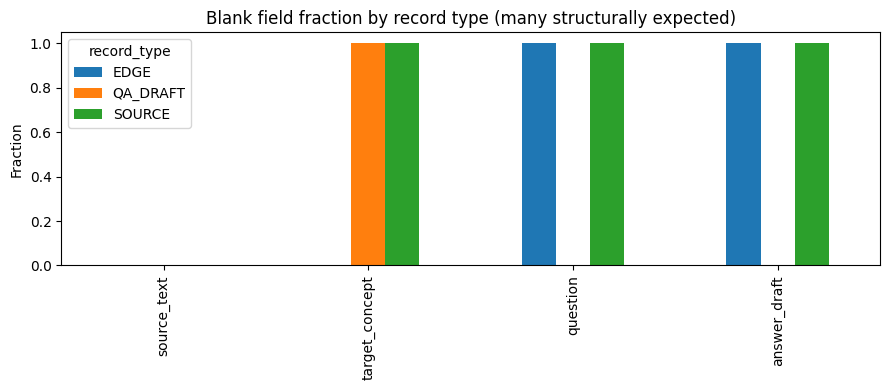

In [8]:
missing_by_type=df.groupby('record_type').apply(lambda part: part[['source_text','target_concept','question','answer_draft']].eq('').mean(),include_groups=False)
missing_by_type.T.plot.bar(figsize=(9,4),title='Blank field fraction by record type (many structurally expected)');plt.ylabel('Fraction');plt.tight_layout();plt.show()

### What did you know about your dataset?

**Measured data profile:** The master CSV contains **5,206 rows × 32 columns**: 145 SOURCE, 4,771 EDGE, 290 QA_DRAFT. No duplicated `record_id`, duplicated SOURCE identifier, or repeated SOURCE `text_hash` was found. The SOURCE text, `source_id`, `domain`, and URL fields are nonblank in all 145 SOURCE records. Blank question or graph fields in other record types are structurally expected; do not impute them. All 145 sources are still `UNREVIEWED`, with `REVIEW_CC_BY_SA` licensing flags.

## ***2. Understanding Your Variables***

In [9]:
print('Columns:', list(df.columns))

Columns: ['record_id', 'record_type', 'dataset_version', 'domain', 'secondary_domains', 'source_id', 'source_title', 'source_url', 'source_revision', 'retrieved_at', 'source_provider', 'license_status', 'review_status', 'split', 'concept_id', 'concept', 'source_text', 'text_hash', 'target_concept', 'target_surface', 'evidence_start', 'evidence_end', 'markov_probability', 'tfidf_score', 'edge_weight', 'question_id', 'question_type', 'question', 'answer_draft', 'evidence_source_ids', 'evidence_quote', 'notes']


In [10]:
display(sources[['text_length','word_count','edge_count','unique_targets','qa_count','avg_edge_weight']].describe().T);display(edges[['markov_probability','tfidf_score','edge_weight']].describe().T)

,count,mean,std,min,25%,50%,75%,max
text_length,145.0,1203.648276,718.206220,208.000000,665.000000,1077.000000,1588.000000,3705.000000
word_count,145.0,178.041379,108.028666,26.000000,92.000000,156.000000,233.000000,583.000000
edge_count,145.0,32.903448,18.414338,7.000000,19.000000,30.000000,43.000000,87.000000
unique_targets,145.0,32.903448,18.414338,7.000000,19.000000,30.000000,43.000000,87.000000
qa_count,145.0,2.000000,0.000000,2.000000,2.000000,2.000000,2.000000,2.000000
avg_edge_weight,145.0,0.052712,0.037768,0.012731,0.026851,0.039974,0.062781,0.196525


,count,mean,std,min,25%,50%,75%,max
markov_probability,4771.0,0.030392,0.023120,0.008403,0.016667,0.022727,0.035714,0.272727
tfidf_score,4771.0,0.147211,0.074010,0.000000,0.102592,0.127822,0.169498,0.817027
edge_weight,4771.0,0.036381,0.032706,0.008781,0.018701,0.025389,0.041952,0.464174


### Variables Description

**Variable dictionary (relevant subset):** `record_type` distinguishes record populations; `source_id` groups evidence; `domain` is the seed-domain label; `split` is the source-level partition; `source_text` is retrieved evidence; `target_concept` is a graph node phrase; `markov_probability` is a per-source transition; `tfidf_score` is a corpus-derived weight; `edge_weight = markov_probability × (1 + tfidf_score)`; `question`/`answer_draft` are **unreviewed drafts**. For all 32 columns, consult `data/processed/data_dictionary.csv`.


### Check Unique Values for each variable.

In [11]:
display(pd.DataFrame({'unique_values':df.nunique(dropna=False)}));display(df.groupby('record_type').size().rename('rows').to_frame())

,unique_values
record_id,5206
record_type,3
dataset_version,1
domain,4
secondary_domains,1
source_id,145
source_title,145
source_url,145
source_revision,145
retrieved_at,145


,rows
record_type,
EDGE,4771
QA_DRAFT,290
SOURCE,145


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Record-type-specific parsing; retain raw original without mutation.
assert df.record_id.is_unique
assert sources.source_id.is_unique
assert sources.split.isin(['train','validation','test']).all()
assert sources.domain.nunique() == 4
assert set(edges.source_id).issubset(set(sources.source_id))
assert set(qa.source_id).issubset(set(sources.source_id))
assert np.allclose(edges.edge_weight, edges.markov_probability*(1+edges.tfidf_score),atol=1e-8,rtol=1e-7)
source_split=sources.set_index('source_id')['split'].to_dict()
assert all(r.source_id in source_split and r.split==source_split[r.source_id] for r in edges.itertuples())
assert all(r.source_id in source_split and r.split==source_split[r.source_id] for r in qa.itertuples())
print('Source integrity, graph formula, and source-level split checks passed.')

Source integrity, graph formula, and source-level split checks passed.


**Observed wrangling outcomes:** Retained the unchanged CSV, partitioned its 3 record types, converted numeric edge scores, aggregated source-level passage length and graph edges, checked graph arithmetic and source-grouped splits. The SOURCE passages average **178.04 words**, and EDGE records total **4,771** with **32.90 edges per source**. Source counts are 40/32/36/37 by AI/ML, Cloud & DevOps, Cybersecurity, and Software Engineering.

Created source-level descriptive features (text length, word count, number of edges, unique targets, Q&A count and edge weights), checked record IDs and source-level splits, and recomputed the stored graph formula. These transformations support EDA only; they do not silently rewrite `master.csv`. The graph is associative, not a verified causal ontology.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

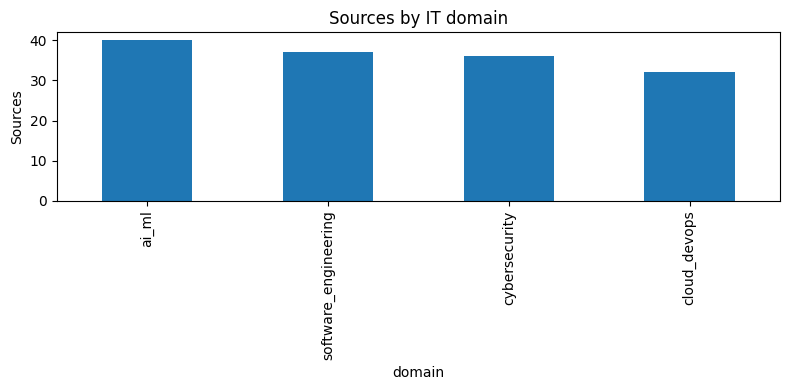

In [13]:
fig, ax = plt.subplots(figsize=(8,4)); sources.domain.value_counts().plot.bar(ax=ax, title='Sources by IT domain'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Coverage across domains** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

Across 145 independent SOURCE records, coverage is AI/ML 40 (27.6%), Software Engineering 37 (25.5%), Cybersecurity 36 (24.8%), Cloud & DevOps 32 (22.1%). The largest class has 40 sources and the smallest has 32 (difference: 8); this is fairly balanced but not a random population sample.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

A relatively balanced four-domain source inventory supports a prototype across all requested IT areas, but 145 documents still limit topical depth; prioritize missing concepts rather than asserting market coverage.

#### Chart - 2

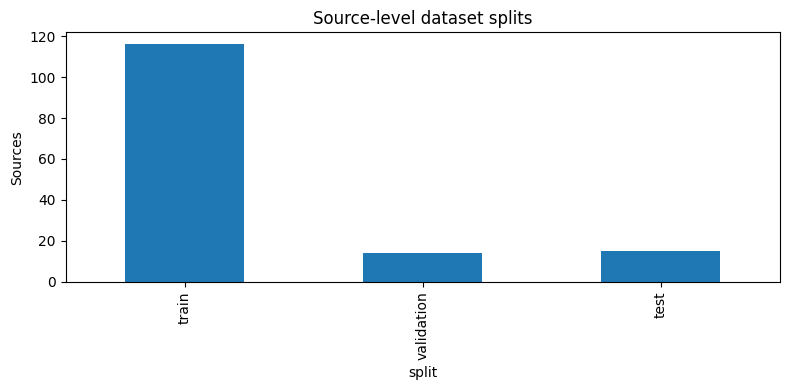

In [14]:
fig, ax = plt.subplots(figsize=(8,4)); sources['split'].value_counts().reindex(['train','validation','test']).plot.bar(ax=ax,title='Source-level dataset splits'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Split balance before model development** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

The predefined source split is 116 training (80.0%), 14 validation (9.7%), and 15 test (10.3%) articles. Keeping all EDGE and QA_DRAFT records aligned with their source ID prevents split leakage.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

A source-level holdout supports fairer auxiliary classifier comparisons. Keep validation/test records out of supervised fitting and hyperparameter selection.

#### Chart - 3

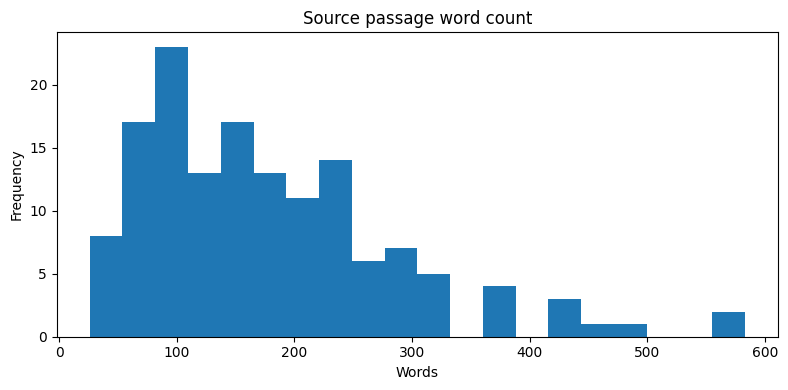

In [15]:
fig, ax = plt.subplots(figsize=(8,4)); sources.word_count.plot.hist(ax=ax,bins=20,title='Source passage word count'); ax.set_xlabel('Words'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Information coverage and short passages** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

Source passages contain 26–583 whitespace-separated words (median 156, mean 178.04, first quartile 92, third quartile 233). Very short sources may provide insufficient retrieval context; long passages may need chunking.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Flag passages near the 26-word minimum for completeness checks and consider chunking 583-word passages for context-window efficiency; do not automatically delete them.

#### Chart - 4

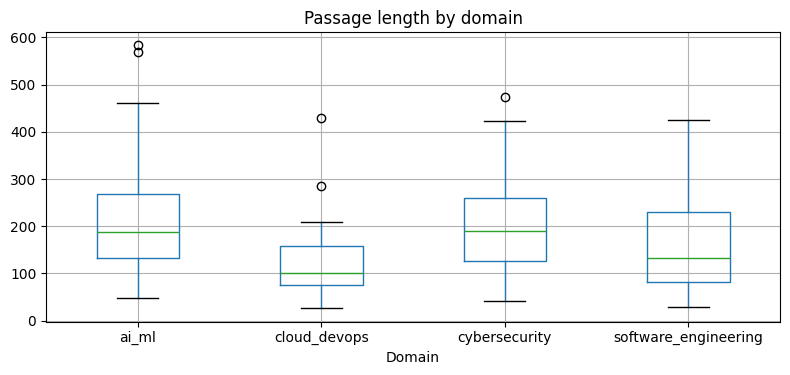

In [16]:
fig, ax = plt.subplots(figsize=(8,4)); sources.boxplot(column='word_count',by='domain',ax=ax); ax.set_title('Passage length by domain'); ax.set_xlabel('Domain'); plt.suptitle(''); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Domain-specific passage length differences** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

Median passage lengths differ by domain: AI/ML 188.5 words; Cloud & DevOps 101.0; Cybersecurity 189.5; Software Engineering 133.0. These are descriptive differences, not evidence of downstream model accuracy.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Domain-specific passage-length differences motivate consistent retrieval token budgets; otherwise longer domains may be favored for reasons unrelated to relevance.

#### Chart - 5

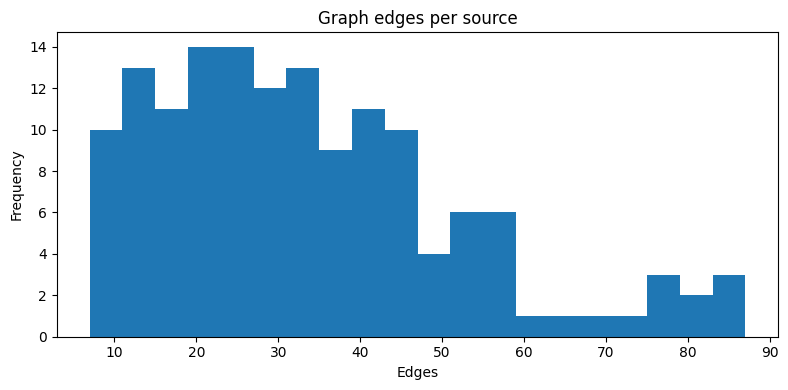

In [17]:
fig, ax = plt.subplots(figsize=(8,4)); sources.edge_count.plot.hist(ax=ax,bins=20,title='Graph edges per source'); ax.set_xlabel('Edges'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Graph density and source connectivity** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

Each source yields 7–87 graph edges (median 30, mean 32.90, interquartile range 19–43). Graph density therefore varies substantially and warrants normalization during graph-based ranking.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Consider top-k or normalized edge budgets per source; dense nodes could dominate graph expansion without such controls.

#### Chart - 6

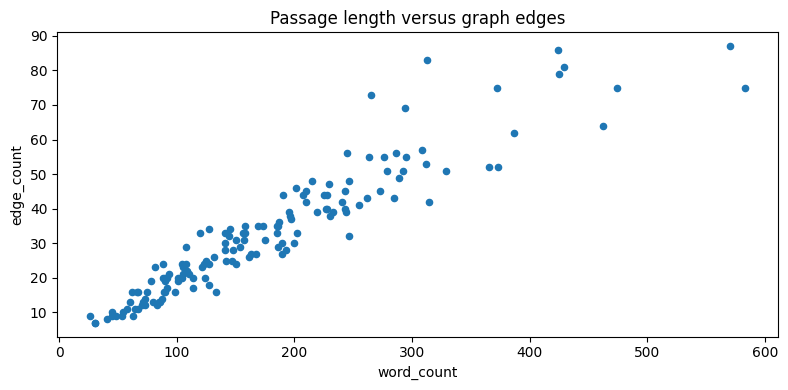

In [18]:
fig, ax = plt.subplots(figsize=(8,4)); sources.plot.scatter(x='word_count',y='edge_count',ax=ax,title='Passage length versus graph edges'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Potential text-length influence on graph size** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

Source passage word count and graph edge count are strongly positively correlated (Pearson r=0.937, n=145). This is expected because longer passages offer more opportunities to extract terms; it does not validate semantic relevance.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

A length-driven edge effect means graph counts should not be sold as knowledge quality. Compare against length-aware and vector-only baselines.

#### Chart - 7

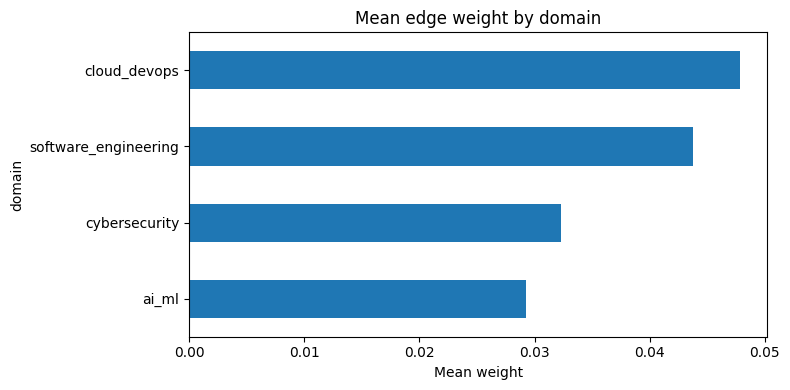

In [19]:
fig, ax = plt.subplots(figsize=(8,4)); edges.groupby('domain').edge_weight.mean().sort_values().plot.barh(ax=ax,title='Mean edge weight by domain'); ax.set_xlabel('Mean weight'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Weighted graph behavior across subdomains** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

Mean Markov–TF-IDF edge weights differ by domain: AI/ML 0.0293, Cloud & DevOps 0.0478, Cybersecurity 0.0323, Software Engineering 0.0437. Because weights are normalized within graph construction, cross-domain means must not be interpreted as relative answer correctness.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use weight statistics to inspect ranking behavior and potential score-calibration differences, then measure Recall@K and answer faithfulness on approved evaluation questions.

#### Chart - 8

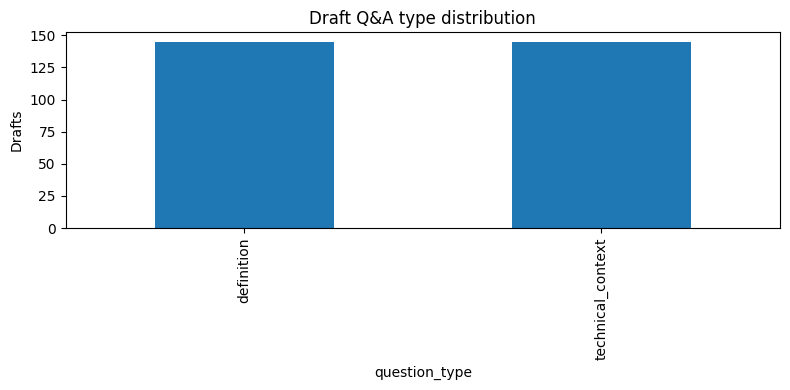

In [20]:
fig, ax = plt.subplots(figsize=(8,4)); qa.question_type.value_counts().plot.bar(ax=ax,title='Draft Q&A type distribution'); ax.set_ylabel('Drafts'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Q&A task diversity** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

The draft Q&A inventory contains exactly 145 definition questions and 145 technical-context questions (290 total). All are drafts, so no question is yet an approved supervised training or gold-evaluation label.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The draft inventory can guide the human review queue, but training and publication must wait for independent evidence review.

#### Chart - 9

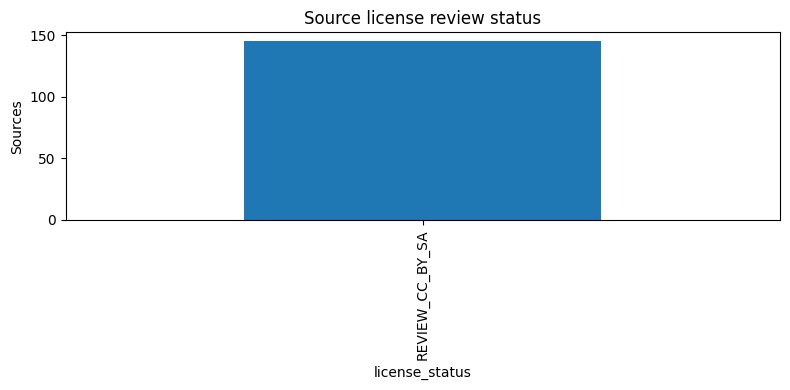

In [21]:
fig, ax = plt.subplots(figsize=(8,4)); sources.license_status.value_counts().plot.bar(ax=ax,title='Source license review status'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Copyright and license audit readiness** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

All 145 source records have license_status=REVIEW_CC_BY_SA. This is a review flag, NOT confirmed clearance for public redistribution or supervised model training.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Complete CC BY-SA attribution and licensing review before distribution or training use; the flag indicates a compliance obligation.

#### Chart - 10

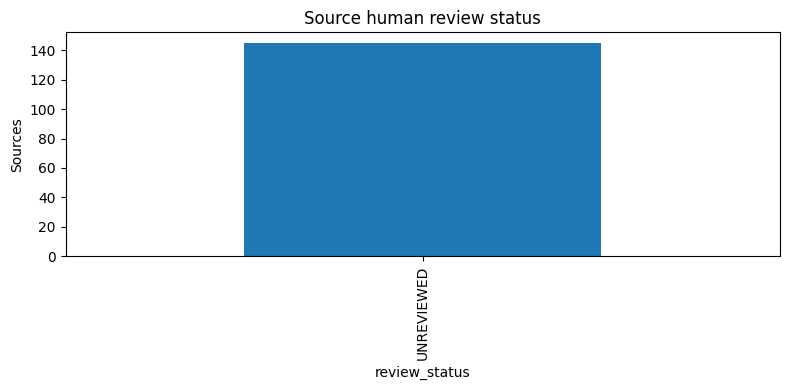

In [22]:
fig, ax = plt.subplots(figsize=(8,4)); sources.review_status.value_counts().plot.bar(ax=ax,title='Source human review status'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Factual review readiness** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

All 145 source records have review_status=UNREVIEWED. Engineering checks passed, but human factual and attribution review remains outstanding.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Prioritize human factual review of all source passages, especially those used for chatbot demonstrations and benchmark creation.

#### Chart - 11

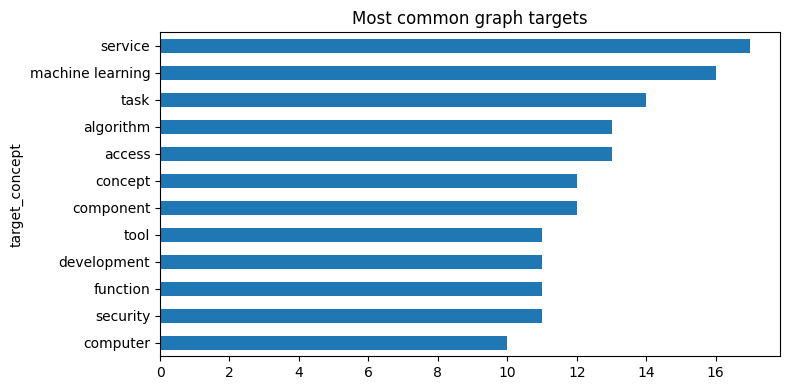

In [23]:
fig, ax = plt.subplots(figsize=(8,4)); edges.target_concept.value_counts().head(12).sort_values().plot.barh(ax=ax,title='Most common graph targets'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Overly frequent generic concepts** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

The most repeated graph target is “service” (17 edges), followed by “machine learning” (16) and “task” (14); “access” and “algorithm” appear 13 times each. Generic targets may create noisy expansions, suggesting a specificity filter.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Down-weight overly generic graph targets such as “service” or “task” to reduce cross-domain retrieval noise; validate the choice experimentally.

#### Chart - 12

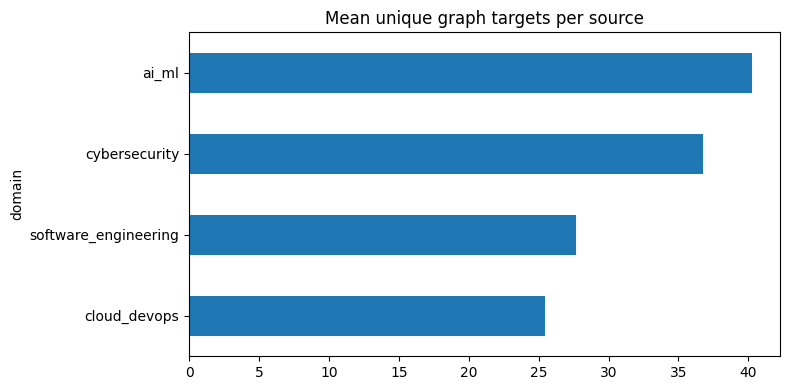

In [24]:
fig, ax = plt.subplots(figsize=(8,4)); sources.groupby('domain').unique_targets.mean().sort_values().plot.barh(ax=ax,title='Mean unique graph targets per source'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Graph concept diversity by domain** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

Average distinct graph targets per source: AI/ML 40.25, Cloud & DevOps 25.44, Cybersecurity 36.72, Software Engineering 27.70. The cross-domain difference is influenced by source lengths and extraction rules; it cannot by itself establish retrieval quality.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Domain-wise expansion budgets may reduce dominance of densely connected topics, but must be tested against independently judged queries.

#### Chart - 13

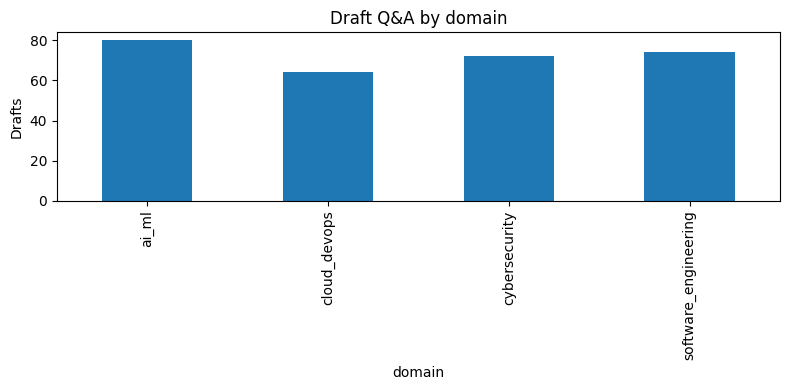

In [25]:
fig, ax = plt.subplots(figsize=(8,4)); sources.groupby('domain').qa_count.sum().plot.bar(ax=ax,title='Draft Q&A by domain'); ax.set_ylabel('Drafts'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Q&A balance for future supervised data** with the appropriate SOURCE, EDGE or Q&A subset.


##### 2. What is/are the insight(s) found from the chart?

There are exactly two draft questions per source. Draft counts by domain are AI/ML 80, Cloud & DevOps 64, Cybersecurity 72, and Software Engineering 74, mirroring source availability.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Equal drafts per source makes review workload predictable; unequal domain totals reflect the source inventory, not domain demand.

#### Chart - 14 - Correlation Heatmap

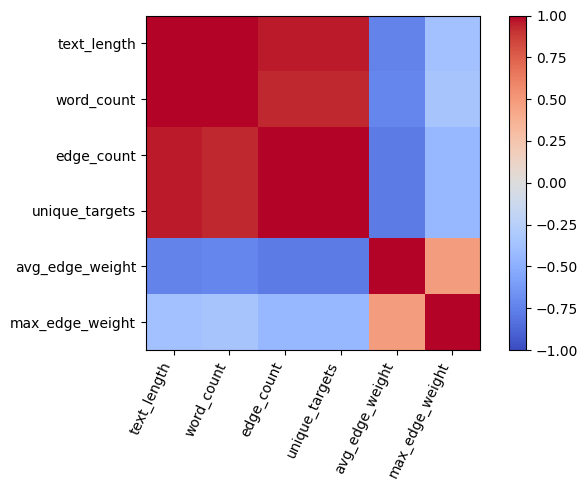

In [26]:
numerics=sources[['text_length','word_count','edge_count','unique_targets','avg_edge_weight','max_edge_weight']]
fig,ax=plt.subplots(figsize=(7,5)); correlation=numerics.corr(numeric_only=True)
im=ax.imshow(correlation, vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(correlation)),correlation.columns,rotation=65,ha='right');ax.set_yticks(range(len(correlation)),correlation.index);fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()

##### 1. Why did you pick the specific chart?

This view explores numerical associations and skew; strong correlation is not causation. Passage length and edge counts are mechanically related, so interpret them cautiously.


##### 2. What is/are the insight(s) found from the chart?

The word-count/edge-count correlation is 0.937. Edge count and unique-target count correlate perfectly (1.000) because this dataset stores one EDGE record per distinct target per source; avoid treating them as independent measurements.

#### Chart - 15 - Pair Plot

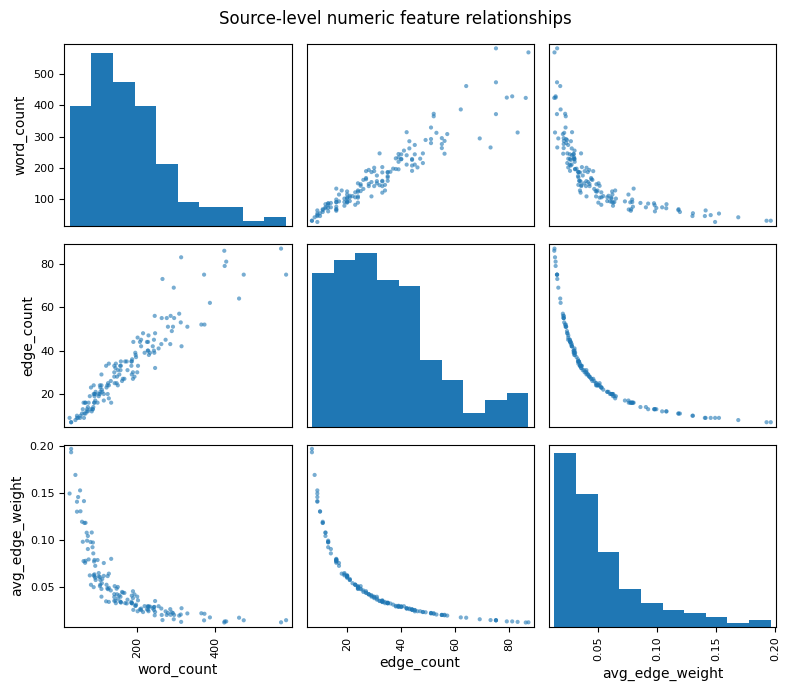

In [27]:
cols=['word_count','edge_count','avg_edge_weight']
sample=sources[cols].dropna().copy()
if len(sample)>1:
    pd.plotting.scatter_matrix(sample, figsize=(8,7), diagonal='hist', alpha=.6)
    plt.suptitle('Source-level numeric feature relationships'); plt.tight_layout(); plt.show()
else:
    print('Insufficient data for a pair plot')

##### 1. Why did you pick the specific chart?

This view explores numerical associations and skew; strong correlation is not causation. Passage length and edge counts are mechanically related, so interpret them cautiously.


##### 2. What is/are the insight(s) found from the chart?

The pair plot makes the same positive word-count/edge-count association visible, while exposing dispersion and long-passage extremes. These descriptive relationships require human inspection of extraction quality; they are not causal findings.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

Prioritize factual and CC BY-SA attribution review for **145 unreviewed sources**, plus manual review of **290 draft questions** before any training or reference-answer evaluation. Audit short articles (**minimum 26 words**), unusually long passages (**maximum 583 words**), and common graph targets such as *service* (**17 edges**). Preserve **116/14/15** source-level splits, then evaluate retrieval using independent judged questions and matched budgets. No chart here measures an uplift in chatbot correctness.

# **Conclusion**

**Actual EDA result:** the candidate corpus contains **145 SOURCE passages**, **4,771 graph edges**, and **290 draft Q&A items**. Source coverage is AI/ML **40**, Cloud & DevOps **32**, Cybersecurity **36**, Software Engineering **37**. Passages have **median 156** and **mean 178.04 words**; source graph connectivity has **median 30** and **mean 32.90 edges**. Passage length is strongly correlated with graph edge count (**Pearson r=0.937**), which is partly expected from extraction mechanics. Structural assertions and the Markov–TF-IDF weight formula pass, but **all 145 sources remain UNREVIEWED** and marked **REVIEW_CC_BY_SA**. The corpus cannot yet be treated as an approved benchmark or fine-tuning set; no GraphRAG superiority or answer accuracy is claimed.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***